# Adversarial attacks on image classifiers

We attack one comma10k frame with the seven adversarial transformations, against three ImageNet classifiers, one per framework:

| Target model | Framework | Adapter (`examples/adapters/`) |
|---|---|---|
| ResNet-50 | PyTorch | `torch_classifier_target.py` (any `torchvision.models` classifier) |
| MobileNetV2 | TensorFlow / Keras | `keras_classifier_target.py` (any `keras.applications` classifier) |
| ViT-B/16 | JAX / Flax | `flax_classifier_target.py` (any Hugging Face Flax classifier) |

The attacks fall in two groups, by what they ask of the target model:

| Attack | Package | Needs | Budget | Randomness |
|---|---|---|---|---|
| `fgsm` | `-fgsm` | `grad` | L-infinity `epsilon`, one step | none |
| `art_fgsm` | `-art` | `grad` | L-infinity `epsilon`, one step | none |
| `art_pgd` | `-art` | `grad` | L-infinity (or L2) `epsilon`, `max_iter` steps | none |
| `art_mim` | `-art` | `grad` | as `art_pgd`, with momentum | none |
| `art_square` | `-art` | `predict` | L-infinity `epsilon`, `max_iter` queries | `seed` |
| `art_simba` | `-art` | `predict` (probabilities) | `epsilon` per pixel value, `max_iter` queries | `seed` |
| `art_hopskipjump` | `-art` | `predict` (top class only) | **none**: the closest misclassified image it finds | `seed` |

The gradient attacks use the adapter's `grad`, the gradient of a loss computed with the framework's autograd. The black-box attacks only call `predict`, the class probabilities, so they also attack models without a gradient. The detection models are in `adversarial-detection.ipynb`: the black-box attacks need class scores, which a detector does not return.

**Environment**: the `kcai` env with `kcai-data-sampling[job,images,fgsm]`, the `-art` package (`pip install -e packages/kcai-data-sampling-art`) and `torchvision`; `tensorflow-cpu` for MobileNetV2, and `jax flax "transformers<5"` for ViT. You also need the comma10k sample from `scripts/fetch_comma10k_sample.py`.

## Setup

Import `torch` **before** `tensorflow`: the reverse order crashes Python with tensorflow-cpu 2.21 and torchvision 0.29.

In [1]:
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow's C++ logs
import torch  # noqa: F401  (before tensorflow, see above)
import torchvision  # noqa: F401

import numpy as np
from PIL import Image

# Work from the repository root, and make the adapters and display helpers importable.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(REPO)
sys.path[:0] = ["examples/adapters", "examples/notebooks"]

from display import show
from kcai_data_sampling_fgsm.api.transformations.fgsm import Fgsm
from kcai_data_sampling_art.api.transformations import ArtFgsm, ArtHopSkipJump, ArtMim, ArtPgd, ArtSimba, ArtSquare

Transformations work on batches. Here `x` is a batch of one RGBA `uint8` image, shape `(1, H, W, 4)`, as the kcai dataloader produces it.

The three classifiers look at a 224×224 image, so we attack the frame at that size. The black-box attacks then run in seconds on a CPU: their cost grows with the number of pixels (`art_simba` tries one pixel value per query, `art_hopskipjump` holds up to `max_eval` noisy copies of the image in memory). Full-size frames are attacked in `adversarial-detection.ipynb`.

`EPSILON` is the attack budget in `[0, 1]` units: 8/255 lets each pixel move by at most 8 grey levels.

(1, 224, 224, 4) uint8



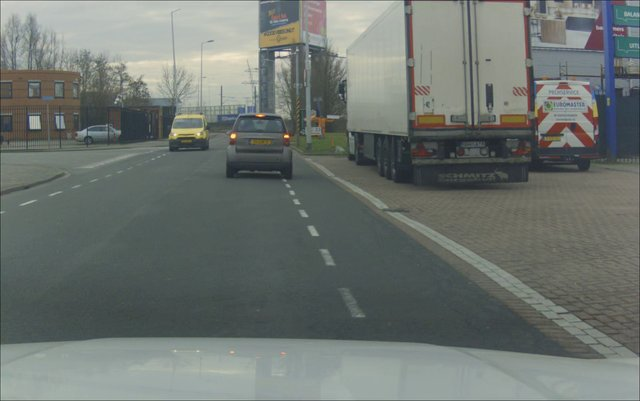
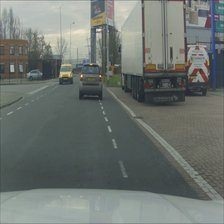

In [2]:
image_path = sorted(Path("examples/data/comma10k_sample/imgs").glob("*.png"))[0]
frame = Image.open(image_path).convert("RGBA")
x = np.asarray(frame.resize((224, 224), Image.Resampling.LANCZOS))[None]
EPSILON = 8 / 255

print(x.shape, x.dtype)
show([("original frame", np.asarray(frame)), ("attacked view (224×224)", x[0])])

Helpers. `attack` builds a transformation from its config, as a job would, and applies it to `x`; `rngs` gives the stochastic attacks one random generator per image, seeded by `seed` and the image id (it returns `None` for the deterministic ones). `report` prints the classifier's top class before and after, and how much the image changed. `perturbation` stretches the change for display (grey = unchanged).

All three classifiers use the standard ImageNet class order; we read the class names from the ViT's config.

In [3]:
from transformers import AutoConfig

IMAGENET = AutoConfig.from_pretrained("google/vit-base-patch16-224").id2label  # class index -> name


def attack(cls, target, **params):
    transformation = cls({"target_model": target, **params})
    return transformation.apply(x, transformation.rngs([image_path.stem]))


def top1(classifier, batch):
    probs = classifier.predict(batch / 255)[0]
    best = int(np.argmax(probs))
    return f"{IMAGENET[best].split(',')[0]} {probs[best]:.0%}"


def report(name, classifier, x_adv):
    delta = np.abs(x_adv.astype(int) - x)
    print(
        f"{name:<16} {top1(classifier, x):<22} -> {top1(classifier, x_adv):<22}"
        f" max change {delta.max():>3} grey levels, {(delta > 0).any(axis=-1).mean():>6.1%} of pixels"
    )


def perturbation(x_adv):
    delta = x_adv[0, ..., :3].astype(int) - x[0, ..., :3]
    return np.clip(128 + delta * 16, 0, 255).astype(np.uint8)

## 1. The three target models

Each adapter reads its model's input size and normalization from the model itself, and keeps that preprocessing inside the gradient computation. `grad` returns the gradient of the cross-entropy of the model's own top-1 class: increasing it pushes the model away from what it currently sees, without needing the image's annotation. `predict` returns the class probabilities.

The weights are downloaded on first use.

In [4]:
from flax_classifier_target import FlaxClassifierTarget
from keras_classifier_target import KerasClassifierTarget
from torch_classifier_target import TorchClassifierTarget

CLASSIFIERS = {
    "ResNet-50": TorchClassifierTarget(model="resnet50"),
    "MobileNetV2": KerasClassifierTarget(model="MobileNetV2"),
    "ViT-B/16": FlaxClassifierTarget(weights="google/vit-base-patch16-224"),
}
for name, classifier in CLASSIFIERS.items():
    print(f"{name:<12} {top1(classifier, x)}")

I0000 00:00:1792415264.571246  189711 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792415272.230285  189711 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


ResNet-50    trailer truck 25%


MobileNetV2  trailer truck 31%


ViT-B/16     trailer truck 64%


## 2. Local `fgsm` and ART `art_fgsm` give the same image

`fgsm` is kcai's own implementation, `x + ε·sign(grad)`; `art_fgsm` runs ART's `FastGradientMethod` on the same `grad`, through the `TargetEstimator` bridge. On every model, both must produce **the same image**.

In [5]:
for name, classifier in CLASSIFIERS.items():
    same = np.array_equal(attack(Fgsm, classifier, epsilon=EPSILON), attack(ArtFgsm, classifier, epsilon=EPSILON))
    print(f"{name:<12} same image: {same}")

ResNet-50    same image: True


MobileNetV2  same image: True


ViT-B/16     same image: True


## 3. Gradient attacks: `art_fgsm`, `art_pgd`, `art_mim`

All three stay within the same L-infinity budget of 8 grey levels. `art_fgsm` takes one step of `epsilon`. `art_pgd` takes `max_iter` (10) steps of `step_fraction * epsilon` (a quarter), each projected back into the budget, so it can follow the loss where one step overshoots. `art_mim` is PGD with momentum: each step also follows the previous directions (`decay`).

In [6]:
GRADIENT = {"art_fgsm": ArtFgsm, "art_pgd": ArtPgd, "art_mim": ArtMim}

adversarial = {}
for name, classifier in CLASSIFIERS.items():
    print(name)
    for algorithm, cls in GRADIENT.items():
        adversarial[name, algorithm] = attack(cls, classifier, epsilon=EPSILON)
        report(algorithm, classifier, adversarial[name, algorithm])

ResNet-50


art_fgsm         trailer truck 25%      -> cab 8%                 max change   8 grey levels, 100% of pixels


art_pgd          trailer truck 25%      -> forklift 7%            max change   8 grey levels,  98% of pixels


art_mim          trailer truck 25%      -> container ship 1%      max change   8 grey levels, 100% of pixels
MobileNetV2


art_fgsm         trailer truck 31%      -> quilt 15%              max change   8 grey levels, 100% of pixels


art_pgd          trailer truck 31%      -> folding chair 4%       max change   8 grey levels,  98% of pixels


art_mim          trailer truck 31%      -> revolver 3%            max change   8 grey levels, 100% of pixels
ViT-B/16


art_fgsm         trailer truck 64%      -> ambulance 25%          max change   8 grey levels, 100% of pixels


art_pgd          trailer truck 64%      -> crutch 98%             max change   8 grey levels,  98% of pixels


art_mim          trailer truck 64%      -> pole 21%               max change   8 grey levels, 100% of pixels


## 4. Black-box attacks: `art_square`, `art_simba`, `art_hopskipjump`

They only call `predict`, through the `TargetClassifier` bridge, and stop as soon as the top class changes. They draw random numbers, so they need a `seed`: with the same seed and image, the result is the same.

- `art_square` adds random squares of `±epsilon` and keeps those that lower the current class's probability, for at most `max_iter` queries (default 100).
- `art_simba` moves one random pixel value at a time by `±epsilon`, for at most `max_iter` values (default 1000), with up to two queries each. Each value changes at most once, so `epsilon` is also its L-infinity budget.
- `art_hopskipjump` has **no budget**. It starts from a noise image that is already misclassified and walks back toward the original, for `max_iter` iterations (default 10) of at most `max_eval` queries each (default 100): check how far it ends.

The cost is the number of queries times the time of one `predict`. With the defaults, `art_simba` and `art_hopskipjump` make a few thousand forward passes per image; on a CPU with three frameworks loaded, that takes tens of minutes. This notebook lowers their budgets (`art_simba` to 300 values, `art_hopskipjump` to 5 iterations of at most 50 queries) so it runs in minutes: weaker attacks than the defaults. We time each attack.

In [7]:
import time

BLACK_BOX = {
    "art_square": (ArtSquare, {"epsilon": EPSILON}),
    "art_simba": (ArtSimba, {"epsilon": EPSILON, "max_iter": 300}),  # default 1000
    "art_hopskipjump": (ArtHopSkipJump, {"max_iter": 5, "max_eval": 50}),  # defaults 10 and 100
}

for name, classifier in CLASSIFIERS.items():
    print(name)
    for algorithm, (cls, params) in BLACK_BOX.items():
        start = time.perf_counter()
        adversarial[name, algorithm] = attack(cls, classifier, seed=0, **params)
        report(algorithm, classifier, adversarial[name, algorithm])
        print(f"{'':<16} {time.perf_counter() - start:.0f} s")

ResNet-50


art_square       trailer truck 25%      -> traffic light 4%       max change   8 grey levels, 100% of pixels
                 1 s


art_simba        trailer truck 25%      -> trailer truck 20%      max change   8 grey levels,   0% of pixels
                 67 s


art_hopskipjump  trailer truck 25%      -> garbage truck 15%      max change  30 grey levels, 100% of pixels
                 17 s
MobileNetV2


art_square       trailer truck 31%      -> pier 13%               max change   8 grey levels, 100% of pixels
                 2 s


art_simba        trailer truck 31%      -> trailer truck 25%      max change   8 grey levels,   0% of pixels
                 203 s


art_hopskipjump  trailer truck 31%      -> garbage truck 26%      max change   6 grey levels,  98% of pixels
                 45 s
ViT-B/16


art_square       trailer truck 64%      -> moving van 42%         max change   8 grey levels,   9% of pixels
                 110 s


art_simba        trailer truck 64%      -> trailer truck 56%      max change   8 grey levels,   0% of pixels
                 466 s


art_hopskipjump  trailer truck 64%      -> container ship 84%     max change 122 grey levels, 100% of pixels
                 123 s


## 5. What the attacks change

The six attacked images of ResNet-50, then their perturbations stretched ×16 (grey = unchanged).


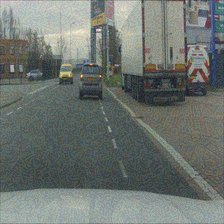
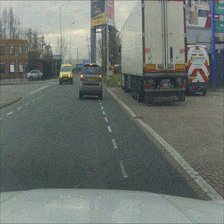
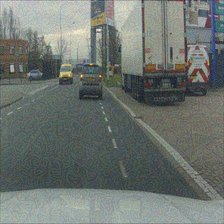
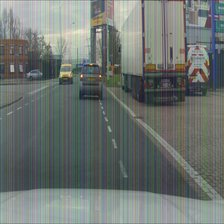
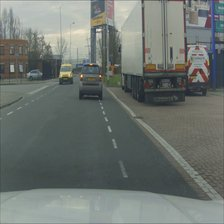
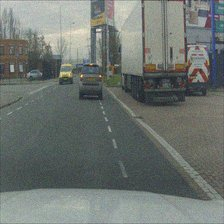


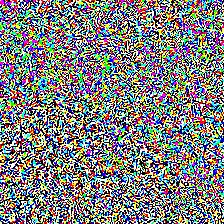
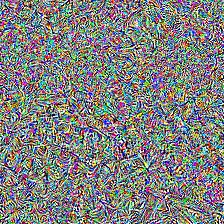
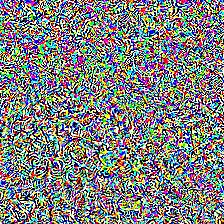
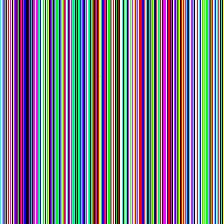
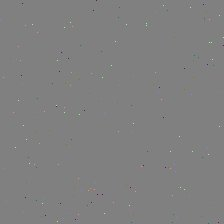
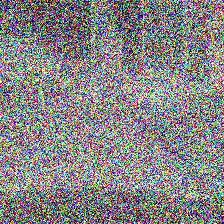

In [8]:
attacks = [*GRADIENT, *BLACK_BOX]
show([(algorithm, adversarial["ResNet-50", algorithm][0]) for algorithm in attacks])
show([(algorithm, perturbation(adversarial["ResNet-50", algorithm])) for algorithm in attacks])

## Takeaways

- **`fgsm` and `art_fgsm` give the same image** on all three models, in PyTorch, TensorFlow and JAX.
- **At 8 grey levels, every gradient attack changes every model's top-1 class.** The iterative ones go further than one step: `art_pgd` turns ViT's "trailer truck" (64%) into "crutch" at 98%, where `art_fgsm` only reaches "ambulance" at 25%.
- **`art_square` is the strong black-box attack here**: it changes all three top-1 classes within the same 8 grey levels, from about 100 queries at most. On ViT it needed more queries and changed only 9% of the pixels.
- **`art_simba` changes no top-1 class with 300 pixel values** (default 1000): it moves at most 300 of the 150,528 values, under 1% of the pixels. It lowers the probability of the class but needs a much larger query budget.
- **`art_hopskipjump` always changes the class, but has no budget**: 30, 6 and 122 grey levels here. Check the change on the output rows, or prefer an epsilon-bounded attack.
- **Black-box attacks cost time, not gradients.** With lowered budgets the black-box section took about 17 minutes on a CPU, against 1.5 minutes for the gradient attacks; most of it on ViT, the slowest `predict`.